# 02 — Predicting social ties with City2Graph and a GNN (toy example)

Can we predict which Boston census tracts are connected by Twitter ties?

1. **Nodes:** census tracts with a few ACS features
2. **Graph:** tracts sharing a border, built with [City2Graph](https://city2graph.net)
3. **Model:** a small GNN learns tract embeddings; two tracts are likely connected if their embeddings are similar and they are close to each other — a gravity model, but with learned neighborhood features

`pip install city2graph torch torch_geometric`

In [1]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import torch
import city2graph as c2g
from torch_geometric.nn import SAGEConv
from sklearn.metrics import roc_auc_score

torch.manual_seed(42)

# ── font sizes ────────────────────────────────────────────────────────────────
FS = 10
FS2 = FS - 2
FS4 = FS - 4

# ── paths ─────────────────────────────────────────────────────────────────────
RAW = "../data/raw/"

# ── Boston ────────────────────────────────────────────────────────────────────
CBSA = 14460

In [2]:
# ── tracts in Boston ──────────────────────────────────────────────────────────
with open(RAW + "censustract_geoms_top50.geojson") as f:
    tracts = gpd.GeoDataFrame.from_features([json.loads(line) for line in f], crs="EPSG:4326")

metro = gpd.read_file(RAW + "metro_areas/metro_areas.shp").to_crs("EPSG:4326")
metro = metro[metro["cbsacode"] == CBSA].geometry.iloc[0]
tracts = tracts[tracts.representative_point().within(metro)]

# ── ACS features (2019) ───────────────────────────────────────────────────────
acs = pd.read_csv(RAW + "acs_data_census_tracts_2012_2020.csv.gz")
acs["log_pop"] = np.log(acs["population2019"])
acs["log_income"] = np.log(acs["income2019"])
acs["bachelor_share"] = acs["education_bachelor2019"] / acs["education_total2019"]
acs["white_share"] = acs["white2019"] / acs["race_total2019"]
features = ["log_pop", "log_income", "bachelor_share", "white_share"]

tracts = tracts[["full_geoid", "geometry"]].merge(acs[["tract_id"] + features], left_on="full_geoid", right_on="tract_id")
tracts = tracts.set_index("tract_id").replace([np.inf, -np.inf], np.nan).dropna().to_crs("EPSG:26919")    # meters

# ── standardise ───────────────────────────────────────────────────────────────
tracts[features] = (tracts[features] - tracts[features].mean()) / tracts[features].std()
print(f"Tracts: {len(tracts)}")

Tracts: 995


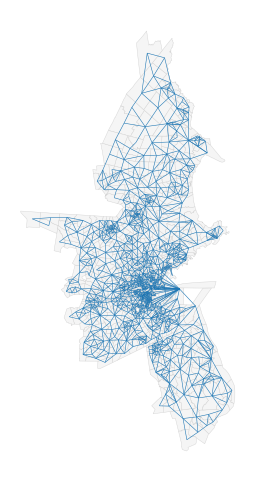

In [3]:
# ── graph: tracts sharing a border (City2Graph) ───────────────────────────────
nodes, edges = c2g.contiguity_graph(tracts, contiguity="queen")

fig, ax = plt.subplots(figsize=(6, 6))
nodes.plot(ax=ax, color="whitesmoke", edgecolor="lightgrey", linewidth=0.3)
edges.plot(ax=ax, color="tab:blue", linewidth=0.4)
ax.axis("off");

In [4]:
# ── convert to PyTorch Geometric ──────────────────────────────────────────────
data = c2g.gdf_to_pyg(nodes, edges, node_feature_cols=features)
node_idx = pd.Series(range(len(nodes)), index=nodes.index)    # tract id -> row in data.x
data

Data(x=[995, 4], edge_index=[2, 5228], edge_attr=[5228, 0], pos=[995, 2], graph_metadata=<city2graph.base.GraphMetadata object at 0x126968690>)

**Target:** pairs of tracts with at least one Twitter tie (positives) and the same number of random pairs (negatives). 20% of the pairs are held out for testing.

In [5]:
# ── positive pairs: Twitter ties between different tracts ─────────────────────
ties = pd.read_csv(RAW + "twitter_tract_tract_edgelist.csv", sep=";")
ties = ties[(ties["tract_home1"] != ties["tract_home2"]) & ties["tract_home1"].isin(node_idx.index) & ties["tract_home2"].isin(node_idx.index)]
pos = torch.tensor(np.array([node_idx[ties["tract_home1"]], node_idx[ties["tract_home2"]]]))

# ── negative pairs: random tract pairs ────────────────────────────────────────
neg = torch.randint(0, len(nodes), pos.shape)

pairs = torch.cat([pos, neg], dim=1)
label = torch.cat([torch.ones(pos.shape[1]), torch.zeros(neg.shape[1])])
test = torch.rand(len(label)) < 0.2

# ── log distance between tract centroids (km) ─────────────────────────────────
xy = torch.tensor(np.column_stack([nodes.centroid.x, nodes.centroid.y]), dtype=torch.float)
log_dist = torch.log((xy[pairs[0]] - xy[pairs[1]]).norm(dim=1) / 1000 + 0.1)
print(f"Pairs: {len(label)}")

Pairs: 43110


In [6]:
# ── baseline: closer tracts are more likely connected ─────────────────────────
auc_distance = roc_auc_score(label[test], -log_dist[test])
print(f"Distance only AUC: {auc_distance:.3f}")

Distance only AUC: 0.788


In [7]:
# ── GNN: tract embeddings from own + neighbours' features ─────────────────────
class TieGNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = SAGEConv(len(features), 32)
        self.conv2 = SAGEConv(32, 32)
        self.distance = torch.nn.Parameter(torch.zeros(1))    # distance decay, learned

    def forward(self, x, edge_index, pairs, log_dist):
        h = self.conv2(self.conv1(x, edge_index).relu(), edge_index)
        # tie score = similarity of the two embeddings + distance decay
        return (h[pairs[0]] * h[pairs[1]]).sum(dim=1) + self.distance * log_dist


# ── train ─────────────────────────────────────────────────────────────────────
model = TieGNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(200):
    optimizer.zero_grad()
    score = model(data.x, data.edge_index, pairs, log_dist)
    loss = torch.nn.functional.binary_cross_entropy_with_logits(score[~test], label[~test])
    loss.backward()
    optimizer.step()

auc_gnn = roc_auc_score(label[test], score[test].detach())
print(f"Distance only AUC: {auc_distance:.3f}")
print(f"GNN + distance AUC: {auc_gnn:.3f}")

Distance only AUC: 0.788
GNN + distance AUC: 0.828


**Next steps**
- Add POI features to the tracts, and transit (`c2g.load_gtfs`) or highway layers as extra graphs
- Use harder negatives: random pairs at similar distances as the real ties
- Repeat for Detroit and New York — does a model trained on one city work in another?